# Módulo 1 — Punto 1.1: Carga, Muestreo y Espacios de Color

**Objetivo:** entender la imagen como una matriz $F(x,y)=I$ y ver qué pasa cuando
reducimos la resolución **espacial** (cantidad de muestras) y la resolución
**cuántica** (cantidad de niveles), y cómo se reparte la información en distintos
espacios de color.

**Cómo usar con otra foto/video:** editar
`config.yaml` (ruta de la imagen o del video y la ROI) y se ejecuta todo de nuevo
(*Run All*).

Toda la lógica de cálculo está en `src/modulo1/carga_muestreo.py`; este notebook
solo la llama y grafica.

## 0. Preparación del entorno

El notebook vive en `notebooks/`, pero el código está en `src/`. Python solo busca
módulos en ciertas carpetas (la lista `sys.path`). Agregamos la **raíz del repo** a
esa lista para poder hacer `from src... import ...`.

In [29]:
# --- Imports de la librería estándar ---
import sys                 # acceso a sys.path (dónde busca Python los módulos)
from pathlib import Path   # manejo de rutas independiente del sistema operativo

# --- Encontrar la raíz del repo ---
# Path.cwd() = carpeta desde donde corre el notebook (normalmente notebooks/). (cwd = current working directory)
# Subimos carpetas hasta encontrar config.yaml: esa es la raíz. (Guía_de_imagenes.../notebooks/config.yaml no existe, pero Guía_de_imagenes.../config.yaml sí)
# Así funciona tanto si VS Code abre el notebook desde notebooks/ como desde la raíz.
raiz = Path.cwd()  
while not (raiz / "config.yaml").exists():
    if raiz.parent == raiz:          # llegamos a "/" sin encontrarlo
        raise FileNotFoundError("No encontré config.yaml en ninguna carpeta superior.")
    raiz = raiz.parent

# Insertamos la raíz al principio de sys.path (posición 0 = máxima prioridad).
if str(raiz) not in sys.path:     # El if se asegura de que sólo lo cargue una vez
    sys.path.insert(0, str(raiz))

# --- Imports de terceros ---
import numpy as np                 # arrays (las imágenes son arrays)
import matplotlib.pyplot as plt    # gráficos
import matplotlib.patches as patches  # para dibujar el rectángulo de la ROI

# --- Imports propios ---
from src.config import cargar_config
from src.modulo1 import carga_muestreo as cm   # En carga_muestreo están las funciones importantes

# Leemos la configuración: un diccionario con todo lo del config.yaml 
# (En config.yaml están los parámetros que dependen de la imagen/ video en particular)
cfg = cargar_config(raiz / "config.yaml")

# Carpeta donde guardamos las figuras (se crea si no existe) y los resultados.
# parents=True crea carpetas intermedias; exist_ok=True no falla si ya existe.
carpeta_res = raiz / cfg["salida"]["carpeta_resultados"]
carpeta_res.mkdir(parents=True, exist_ok=True)

print("Raíz del repo:", raiz)
print("Resultados en:", carpeta_res)

Raíz del repo: c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB
Resultados en: c:\Users\ronal\Documents\Q2 2026\PSIB\Guia_Ojo\Guia-de-imagenes-biomedicas-G9-PSIB\results\modulo1


## 1.1.1 — Frame representativo y Región de Interés (ROI)

`obtener_frame` lee la imagen indicada en el config (o extrae un frame del video si
`imagen_path` es `null`). OpenCV lee en orden **BGR**; la función ya lo convierte a
**RGB** para que matplotlib muestre los colores correctos.

La ROI está definida en **fracciones** del ancho/alto. Dibujamos una grilla cada 10 %
para que, con otra foto, sea fácil leer qué valores poner en el config.

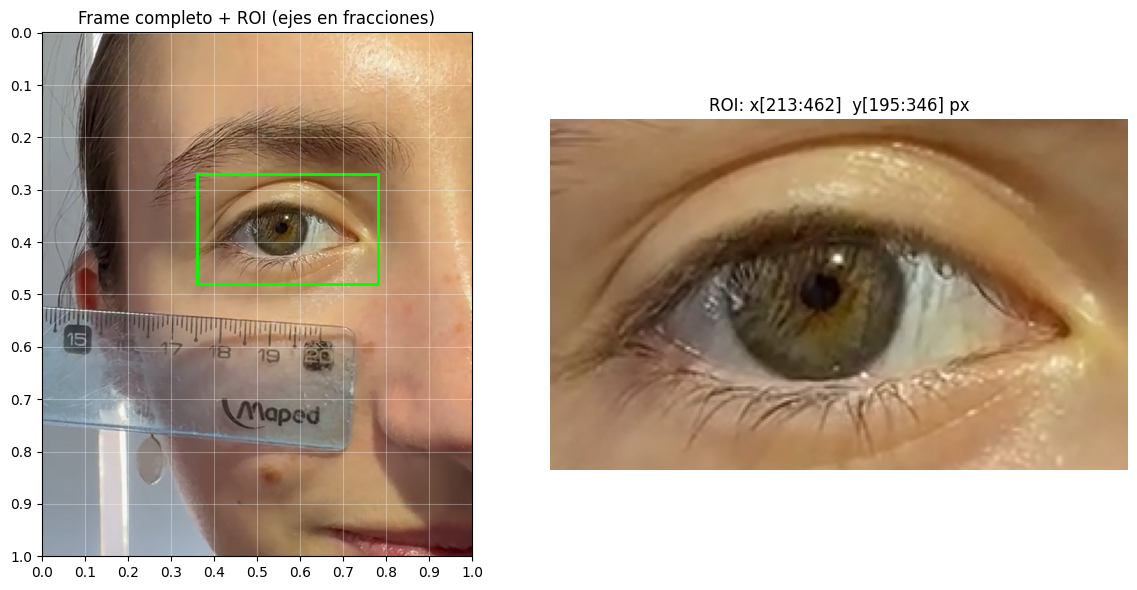

In [30]:
# Frame del video completo en RGB, como array (alto, ancho, 3) de uint8
img = cm.obtener_frame(cfg, raiz)

# Convertimos la ROI del config (la defini yo) (fracciones) a píxeles, solo para dibujarla
x0, x1, y0, y1 = cm.roi_a_pixeles(img.shape, cfg["roi"]) # Mirar la función en carga_muestreo 
# --> multiplica las fracciones por el número de píxeles del ancho y alto de la imagen y redondea

# Recorte de la ROI (copia independiente del original)
roi = cm.recortar_roi(img, cfg["roi"])

alto, ancho = img.shape[:2]

# fig = la figura entera; ax = lista de "ejes" (subgráficos). 1 fila, 2 columnas.
fig, ax = plt.subplots(1, 2, figsize=(12, 6))


# Acá lo ponemos todo lindo
# --- Izquierda: imagen completa con la ROI marcada ---
ax[0].imshow(img)   # imshow interpreta un array (alto, ancho, 3) como RGB
# Rectangle((x, y), ancho, alto): (x, y) es la esquina superior izquierda
ax[0].add_patch(patches.Rectangle((x0, y0), x1 - x0, y1 - y0,
                                  fill=False, edgecolor="lime", linewidth=2))
# Grilla cada 10 %: marcas en píxeles pero con etiquetas en fracción
fr = np.linspace(0, 1, 11)                 # 0.0, 0.1, ..., 1.0
ax[0].set_xticks(fr * ancho, [f"{f:.1f}" for f in fr])
ax[0].set_yticks(fr * alto, [f"{f:.1f}" for f in fr])
ax[0].grid(color="white", alpha=0.3)
ax[0].set_title("Frame completo + ROI (ejes en fracciones)")

# --- Derecha: la ROI recortada ---
ax[1].imshow(roi)
ax[1].set_title(f"ROI: x[{x0}:{x1}]  y[{y0}:{y1}] px")
ax[1].axis("off")    # sin ejes: solo la imagen

plt.tight_layout()   # acomoda márgenes para que no se pisen títulos
fig.savefig(carpeta_res / "1_1_1_roi.png", dpi=150)
plt.show()

## 1.1.2 — Dimensiones y profundidad de bits

- `shape` devuelve **(alto, ancho, canales)**: primero filas (Y), después columnas (X).
- `dtype = uint8` → 8 bits por canal → $2^8 = 256$ niveles (0 a 255).
- Bits por píxel = bits por canal × canales (RGB de 8 bits = 24 bpp ≈ 16,7 millones de colores).

Nota: el archivo PNG original traía 4 canales (RGBA, con transparencia); al cargar
descartamos el alfa porque no aporta información del ojo.

In [31]:
# Recorremos imagen completa y ROI e imprimimos cada propiedad
for nombre, im in [("Frame completo", img), ("ROI", roi)]:
    info = cm.info_imagen(im)      # diccionario con las propiedades
    print(f"--- {nombre} ---")
    print(f"  Dimensiones (Ancho x Alto): {info['ancho']} x {info['alto']} px")
    print(f"  Canales: {info['canales']}")
    print(f"  Tipo de dato: {info['dtype']} -> {info['bits_por_canal']} bits/canal "
          f"({info['niveles_posibles']} niveles), {info['bits_por_pixel']} bits/píxel")
    print(f"  Rango usado: [{info['min']}, {info['max']}]")
    print(f"  Total de píxeles: {info['total_pixeles']:,}")

--- Frame completo ---
  Dimensiones (Ancho x Alto): 592 x 721 px
  Canales: 3
  Tipo de dato: uint8 -> 8 bits/canal (256 niveles), 24 bits/píxel
  Rango usado: [0, 255]
  Total de píxeles: 426,832
--- ROI ---
  Dimensiones (Ancho x Alto): 249 x 151 px
  Canales: 3
  Tipo de dato: uint8 -> 8 bits/canal (256 niveles), 24 bits/píxel
  Rango usado: [0, 255]
  Total de píxeles: 37,599


## 1.1.3 — Resolución espacial: submuestreo al 50 %, 25 % y 5 %

Submuestrear = tomar menos muestras por unidad de espacio. Usamos al **vecino más
cercano** (sin promediar) y obtuvimos: pérdida de
detalle fino (pestañas, textura del iris, borde pupilar) y *aliasing*.

Para comparar a igual tamaño, cada versión se vuelve a ampliar replicando píxeles:
por eso se ven bloques. **La información perdida no se recupera al ampliar.**

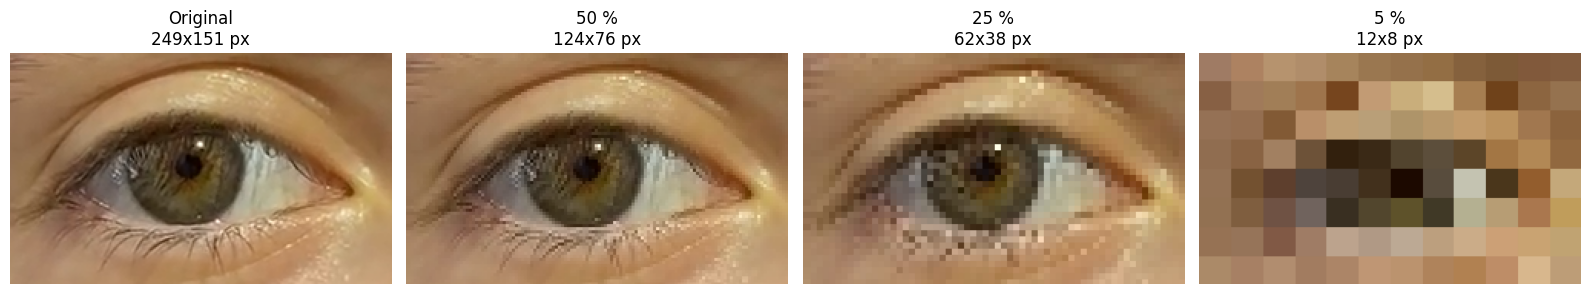

In [32]:
escalas = cfg["modulo1"]["escalas_submuestreo"]   # [0.5, 0.25, 0.05]

# Armamos la salida: 1 columna para el original + 1 por cada escala 
fig, ax = plt.subplots(1, len(escalas) + 1, figsize=(4 * (len(escalas) + 1), 3.5))

ax[0].imshow(roi)
ax[0].set_title(f"Original\n{roi.shape[1]}x{roi.shape[0]} px")

# Vamos iterando por cada escala de submuestreo y mostrando la versión chica y la re-ampliada
for i, esc in enumerate(escalas, start=1):        # enumerate da índice + valor
    # Versión realmente chica (para informar cuántos píxeles quedan) --> Se toma un píxel cada N, entonces queda una imagen más chica.
    chica = cm.submuestrear(roi, esc, volver_a_tamano_original=False) # Mirar funcion en carga_muestreo
    # Versión re-ampliada al tamaño original (para comparar visualmente) --> Se vuelve al tamaño original, 
    # pero con menos información (menos píxeles). Se ve pixelada.
    vista = cm.submuestrear(roi, esc, volver_a_tamano_original=True)
    ax[i].imshow(vista)
    ax[i].set_title(f"{esc*100:.0f} %\n{chica.shape[1]}x{chica.shape[0]} px")

for a in ax:
    a.axis("off")
plt.tight_layout()
fig.savefig(carpeta_res / "1_1_3_submuestreo.png", dpi=150)
plt.show()

**Para analizar:** al 50 % la pupila y el iris siguen nítidos; al 25 % se pierden las
pestañas y la textura fina del estroma; al 5 % quedan pocos píxeles: se distingue que
hay un ojo, pero el contorno de la pupila es una "escalera" de bloques y medir su
diámetro tendría un error del orden del tamaño del bloque.

## 1.1.4 — Cuantización: 8 → 4 → 2 bits

Con $k$ bits hay $L = 2^k$ niveles. Cada píxel se lleva al centro del intervalo
de ancho $256/L$ al que pertenece. Se muestra en color (por canal) y en grises,
y se cuenta cuántos niveles distintos quedan para verificar.

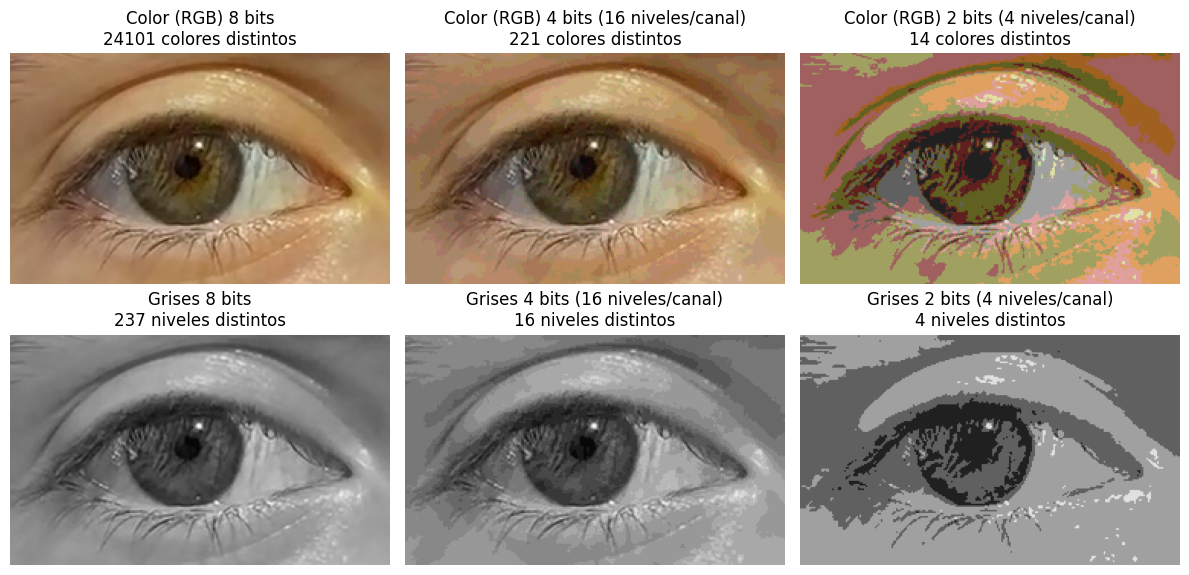

In [33]:
bits_lista = cfg["modulo1"]["bits_cuantizacion"]   # [4, 2]

# Convertimos a escala de grises usando la fórmula estándar:
# Y = 0.299 R + 0.587 G + 0.114 B   (pesos según la sensibilidad del ojo: máxima en verde)
# np.dot multiplica el último eje (los 3 canales) por el vector de pesos y suma.
gris = np.dot(roi[..., :3].astype(np.float32), [0.299, 0.587, 0.114]) # Usamos float.32 pq 
# admite valores grandes, despues lo pasamos a 8 bits (uint8), como venimos trabajando.
gris = np.clip(gris, 0, 255).astype(np.uint8)  # volvemos a uint8 (0..255)

# Que se ve a la salida de esta celda: una fila para la imagen en color y otra para la versión en grises, 
# y una columna para cada cantidad de bits de cuantización.
filas = [("Color (RGB)", roi, None), ("Grises", gris, "gray")]
fig, ax = plt.subplots(2, len(bits_lista) + 1, figsize=(4 * (len(bits_lista) + 1), 6))

for f, (nombre, base, cmap) in enumerate(filas):
    # cmap="gray" + vmin/vmax fijos (0 negro y 255 blanco): sin esto matplotlib "estira" el contraste
    # automáticamente y no veríamos la degradación real.
    kw = dict(cmap=cmap, vmin=0, vmax=255) if cmap else {}
    ax[f, 0].imshow(base, **kw)
    ax[f, 0].set_title(f"{nombre} 8 bits\n{cm.contar_niveles(base)} {'colores' if base.ndim == 3 else 'niveles'} distintos")
    for c, b in enumerate(bits_lista, start=1):
        q = cm.cuantizar(base, b)   # Acá se hace la cuantización a b bits!! Mirar carga_muestreo
        ax[f, c].imshow(q, **kw)
        ax[f, c].set_title(f"{nombre} {b} bits ({2**b} niveles/canal)\n"
                           f"{cm.contar_niveles(q)} {'colores' if q.ndim == 3 else 'niveles'} distintos")

for a in ax.ravel():   # ravel aplana la grilla 2x3 de ejes a una lista
    a.axis("off")
plt.tight_layout()
fig.savefig(carpeta_res / "1_1_4_cuantizacion.png", dpi=150)
plt.show()

**Para analizar:** con 4 bits (16 niveles) casi no se nota a simple vista; aparecen
leves bandas en zonas de gradiente suave (piel, esclerótica). Con 2 bits (4 niveles
por canal → 64 colores en RGB) aparecen **falsos contornos**: el gradiente de la piel
se parte en escalones y los colores se vuelven irreales (piel rosada/verdosa). En
grises con 2 bits la pupila queda en el mismo nivel que las zonas oscuras del iris y
las pestañas: con tan pocos niveles ya no se puede separar la pupila por intensidad.

## 1.1.5 — Espacios de color

### Canales R, G, B por separado
Cada canal es una matriz 2D: se ve en grises (blanco = mucho de ese color).

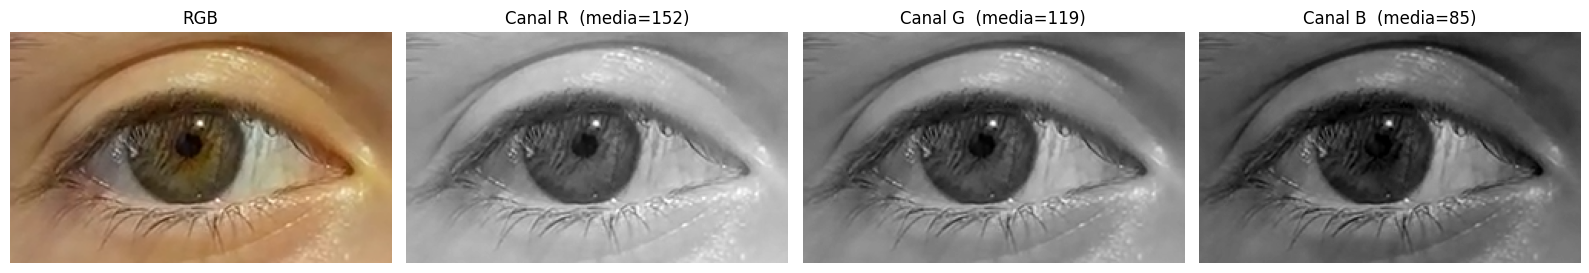

In [34]:
canales = cm.separar_rgb(roi)   # {"R": matriz, "G": matriz, "B": matriz}

fig, ax = plt.subplots(1, 4, figsize=(16, 3.5))
ax[0].imshow(roi)
ax[0].set_title("RGB")
for i, (nombre, canal) in enumerate(canales.items(), start=1): # Itera por cada matriz de canal (R, G, B)
    ax[i].imshow(canal, cmap="gray", vmin=0, vmax=255)
    ax[i].set_title(f"Canal {nombre}  (media={canal.mean():.0f})")
for a in ax:
    a.axis("off")
plt.tight_layout()
fig.savefig(carpeta_res / "1_1_5_canales_rgb.png", dpi=150)
plt.show()

### RGB → HSV
- **H** (matiz) en OpenCV va de 0 a 179 (grados/2). Se muestra con un mapa de color
  cíclico (`hsv`) porque 0 y 179 son colores vecinos (rojo).
- **S** (saturación) y **V** (valor = max(R,G,B)) van de 0 a 255.

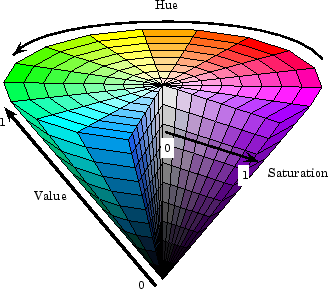

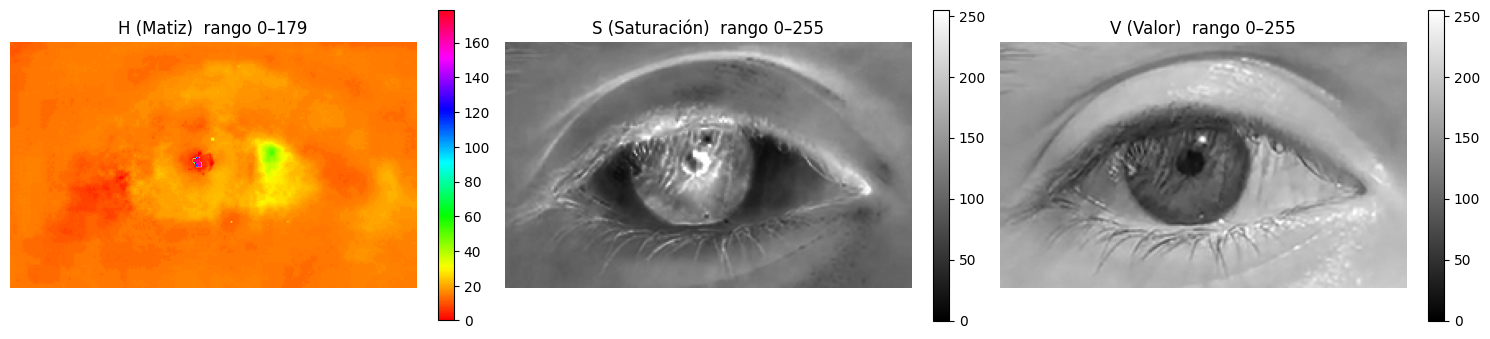

In [35]:
hsv = cm.rgb_a_hsv(roi)   # {"H":..., "S":..., "V":...}

# Para cada componente: (mapa de colores, valor máximo, descripción)
estilo = {"H": ("hsv", 179, "Matiz"), "S": ("gray", 255, "Saturación"), "V": ("gray", 255, "Valor")}

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for i, (nombre, comp) in enumerate(hsv.items()):
    cmap, vmax, desc = estilo[nombre]
    im = ax[i].imshow(comp, cmap=cmap, vmin=0, vmax=vmax)
    ax[i].set_title(f"{nombre} ({desc})  rango 0–{vmax}")
    ax[i].axis("off")
    fig.colorbar(im, ax=ax[i], fraction=0.035)   # barra de referencia de valores
plt.tight_layout()
fig.savefig(carpeta_res / "1_1_5_hsv.png", dpi=150)
plt.show()

**Para analizar:**
- **R** muestra la piel muy clara y el iris oscuro; **B** es el más oscuro y ruidoso
  (las cámaras de celular tienen menos sensibilidad en azul).
- **V** separa muy bien la pupila (mínimo de brillo) del iris, independientemente del
  color de ojos: es un buen candidato para la segmentación.
- **H** es casi uniforme (naranja = tono piel) y solo cambia en la pupila, el
  reflejo y la esclerótica: en zonas oscuras o grises el matiz está mal definido
  (si max = min, no hay "color") y toma valores poco confiables.
- **S** es alta en el iris (tiene color) y baja en la esclerótica (blanca). En la
  pupila S también puede salir alta y ruidosa: con V muy bajo, S = (max−min)/max
  divide por un número chico y se vuelve inestable.